<a href="https://colab.research.google.com/github/Charitha-Perumalla7/DAV-Lab2026-27/blob/main/dav_exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
# Load Iris dataset
iris = load_iris()

# Select two features
X = iris.data[:, [0, 2]]

# Convert into DataFrame
df = pd.DataFrame(X, columns=['Sepal Length', 'Petal Length'])

print("First five rows of dataset:")
print(df.head())

First five rows of dataset:
   Sepal Length  Petal Length
0           5.1           1.4
1           4.9           1.4
2           4.7           1.3
3           4.6           1.5
4           5.0           1.4


In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[-0.90068117 -1.34022653]
 [-1.14301691 -1.34022653]
 [-1.38535265 -1.39706395]
 [-1.50652052 -1.2833891 ]
 [-1.02184904 -1.34022653]]


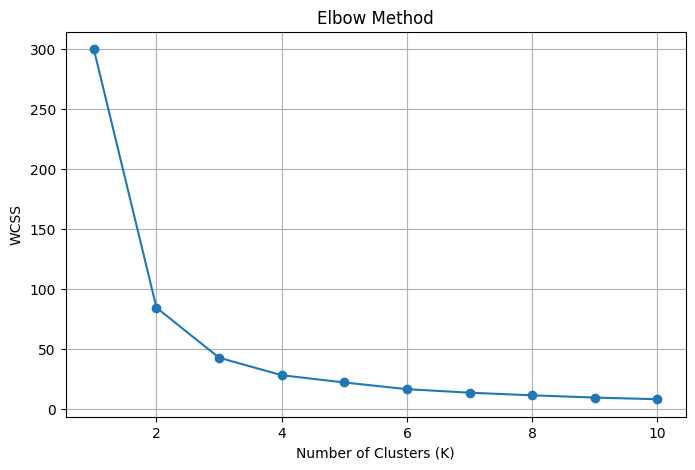

In [4]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.grid(True)
plt.show()

In [5]:
# Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_kmeans = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataset
df['Cluster'] = y_kmeans

print("Clustered Dataset:")
print(df.head(10))

Clustered Dataset:
   Sepal Length  Petal Length  Cluster
0           5.1           1.4        1
1           4.9           1.4        1
2           4.7           1.3        1
3           4.6           1.5        1
4           5.0           1.4        1
5           5.4           1.7        1
6           4.6           1.4        1
7           5.0           1.5        1
8           4.4           1.4        1
9           4.9           1.5        1


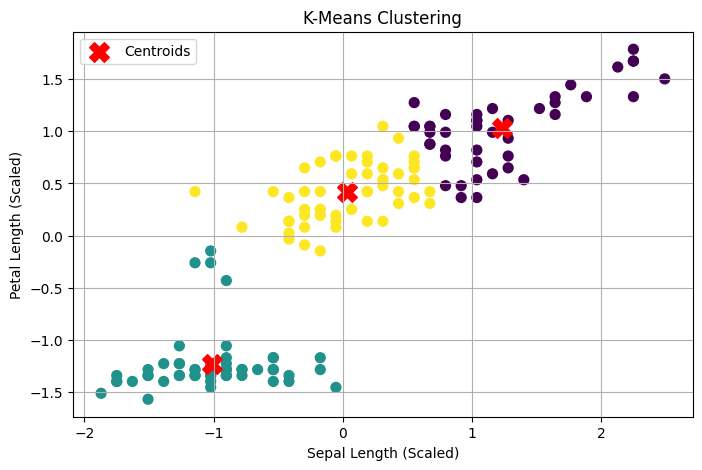

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title('K-Means Clustering')
plt.xlabel('Sepal Length (Scaled)')
plt.ylabel('Petal Length (Scaled)')

plt.legend()
plt.grid(True)
plt.show()